# PROYEK UTS PEMBELAJARAN MENDALAM

## Klasifikasi Tutupan Lahan Citra Satelit Sentinel-2 Menggunakan EfficientNet-B0 dengan Grad-CAM dan Confidence Threshold

- **Mata kuliah:** Pembelajaran Mendalam
- **Kelompok:** 8
- **Semester:** Ganjil 2026/2027
- **Dataset:** [EuroSAT RGB](https://zenodo.org/records/7711810)

**Anggota Kelompok 8:**

1. Jordanniel Saor Sihombing — 2311120148
2. Jordani Brema Barus — 231112650
3. Kevin Rorista Kaban — 231112119
4. Fadillah Rasyd Barus — 231112885
5. M. Alfi Syahrin — 231112853
6. Fikri Anwar — 231112145

Notebook dapat dijalankan dengan mengunggah **EuroSAT_RGB.zip** saja; modul proyek sudah tertanam pada section pertama. Di Colab pilih GPU bila tersedia, kemudian jalankan section secara berurutan. Satu pembagian 70/15/15 disimpan dan divalidasi dengan SHA-256. Ukuran input asli 64×64 berlaku untuk kedua CNN; ini berbeda dari preset ImageNet 224×224.

**Peta section**

1. Lingkungan dan konfigurasi
2. Audit dataset dan EDA
3. Preprocessing, split, dan arsitektur
4. CNN dasar sebagai baseline
5. EfficientNet-B0 tahap feature extraction
6. Fine-tuning dan penguncian checkpoint
7. Kalibrasi validasi dan evaluasi holdout
8. Interpretasi Grad-CAM
9. Confidence threshold sebelum dan sesudah penolakan
10. Kesimpulan hasil dan ekspor model

Setiap section menampilkan **Hasil yang Diperoleh** dan **Temuan Awal** dari variabel hasil eksekusi. Evaluasi test dijalankan setelah checkpoint dan ambang confidence ditetapkan; hasil tersimpan dapat dibaca ulang tanpa menghitung ulang test.


In [1]:
from pathlib import Path
import base64, json, os, shutil, subprocess, sys, zipfile, zlib
from IPython.display import display, Markdown, Image as IPImage

SOURCE_SNAPSHOT = json.loads(zlib.decompress(base64.b64decode('...')).decode())
candidates = [Path.cwd(), Path.cwd().parent]
PROJECT = next((path for path in candidates if (path/'src/train.py').is_file()), Path.cwd()/'eurosat_kelompok8')
PROJECT.mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT)
# Di repository lokal, gunakan modul yang tersedia tanpa menimpa perubahan pengguna.
# Di Colab, siapkan modul yang belum tersedia dari salinan sumber notebook.
for relative, source in SOURCE_SNAPSHOT.items():
    target = Path(relative)
    if not target.exists():
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_text(source, encoding='utf8')
print(f'Modul pendukung siap: {len(SOURCE_SNAPSHOT)} berkas.')


Modul pendukung siap: 28 berkas.


## 1 Lingkungan dan konfigurasi

Menyiapkan kode yang dapat direproduksi dan mencatat perangkat aktual. Pengaturan eksperimen berasal dari `experiment_config.json`.


In [2]:
from pathlib import Path
import os,sys,json,subprocess,importlib.util
from IPython.display import display,Markdown,Image as IPImage
needed={'torch':'torch','torchvision':'torchvision','PIL':'Pillow','numpy':'numpy','sklearn':'scikit-learn',
        'matplotlib':'matplotlib','pandas':'pandas','gradio':'gradio','tqdm':'tqdm'}
if any(importlib.util.find_spec(name) is None for name in needed):
    subprocess.run([sys.executable,'-m','pip','install','-q','-r','requirements.txt'],check=True)
import torch, torchvision, numpy as np, pandas as pd
if str(PROJECT.resolve()) not in sys.path:sys.path.insert(0,str(PROJECT.resolve()))
from src.data import seed_everything
cfg=json.loads(Path('experiment_config.json').read_text())
seed_everything(cfg['seed'])

def run_stage(stage):
    result=subprocess.run([sys.executable,'scripts/run_experiment.py','--stage',stage],capture_output=True,text=True)
    print(result.stdout)
    if result.returncode:raise RuntimeError(result.stderr[-6000:])

display(Markdown(f"**Hasil yang Diperoleh**\n\nPython `{sys.version.split()[0]}`, PyTorch `{torch.__version__}`, TorchVision `{torchvision.__version__}`, perangkat **{'GPU '+torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}**. Input **{cfg['image_size']}×{cfg['image_size']}**, batch **{cfg['batch_size']}**, seed **{cfg['seed']}**.\n\n**Temuan Awal**\n\nSumber kode tertanam telah disiapkan; seluruh 27.000 citra digunakan. GPU dapat mempercepat pelatihan, tetapi CPU juga didukung."))


**Hasil yang Diperoleh**

Python `3.12.14`, PyTorch `2.5.1+cpu`, TorchVision `0.20.1+cpu`, perangkat **CPU**. Input **64×64**, batch **64**, seed **42**.

**Temuan Awal**

Sumber kode tertanam telah disiapkan; seluruh 27.000 citra digunakan. GPU dapat mempercepat pelatihan, tetapi CPU juga didukung.

## 2 Audit dataset dan EDA

Memeriksa berkas JPEG, jumlah kelas, resolusi, duplikat byte-identik, distribusi kelas, tiga sampel per kelas, dan histogram RGB. ZIP dengan nama `(1)` atau `(2)` juga diterima.


{
  "total": 27000,
  "counts": {
    "AnnualCrop": 3000,
    "Forest": 3000,
    "HerbaceousVegetation": 3000,
    "Highway": 2500,
    "Industrial": 2500,
    "Pasture": 2000,
    "PermanentCrop": 2500,
    "Residential": 3000,
    "River": 2500,
    "SeaLake": 3000
  },
  "sizes": {
    "(64, 64)": 27000
  },
  "modes": {
    "RGB": 27000
  },
  "verified_broken_files": [],
  "estimated_channel_means_sample": [
    87.33999633789062,
    96.72000122070312,
    103.69999694824219
  ],
  "channel_sample_images": 1350,
  "splits": {
    "train": 18900,
    "val": 4050,
    "test": 4050
  },
  "limitation": "Identical-byte hashes do not detect near-duplicate imagery or spatial leakage."
}


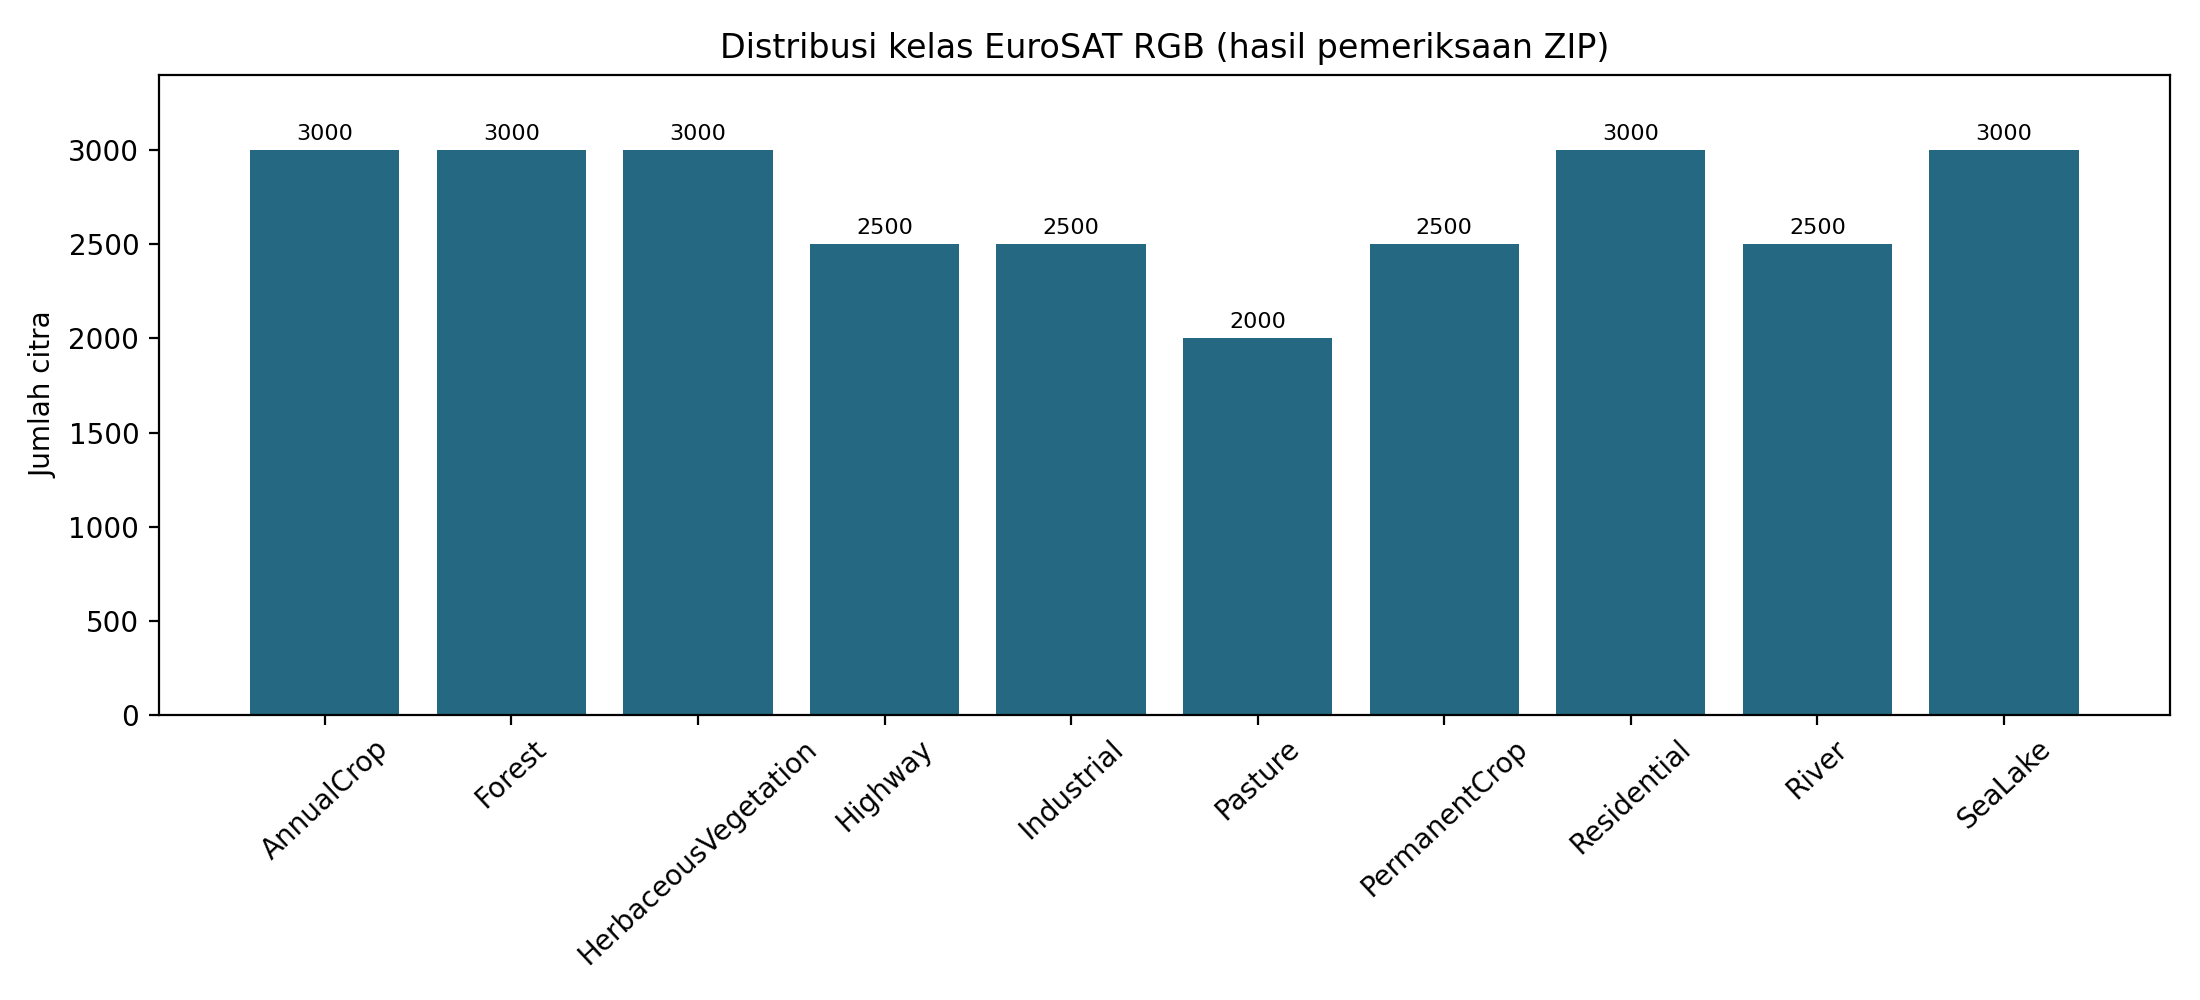

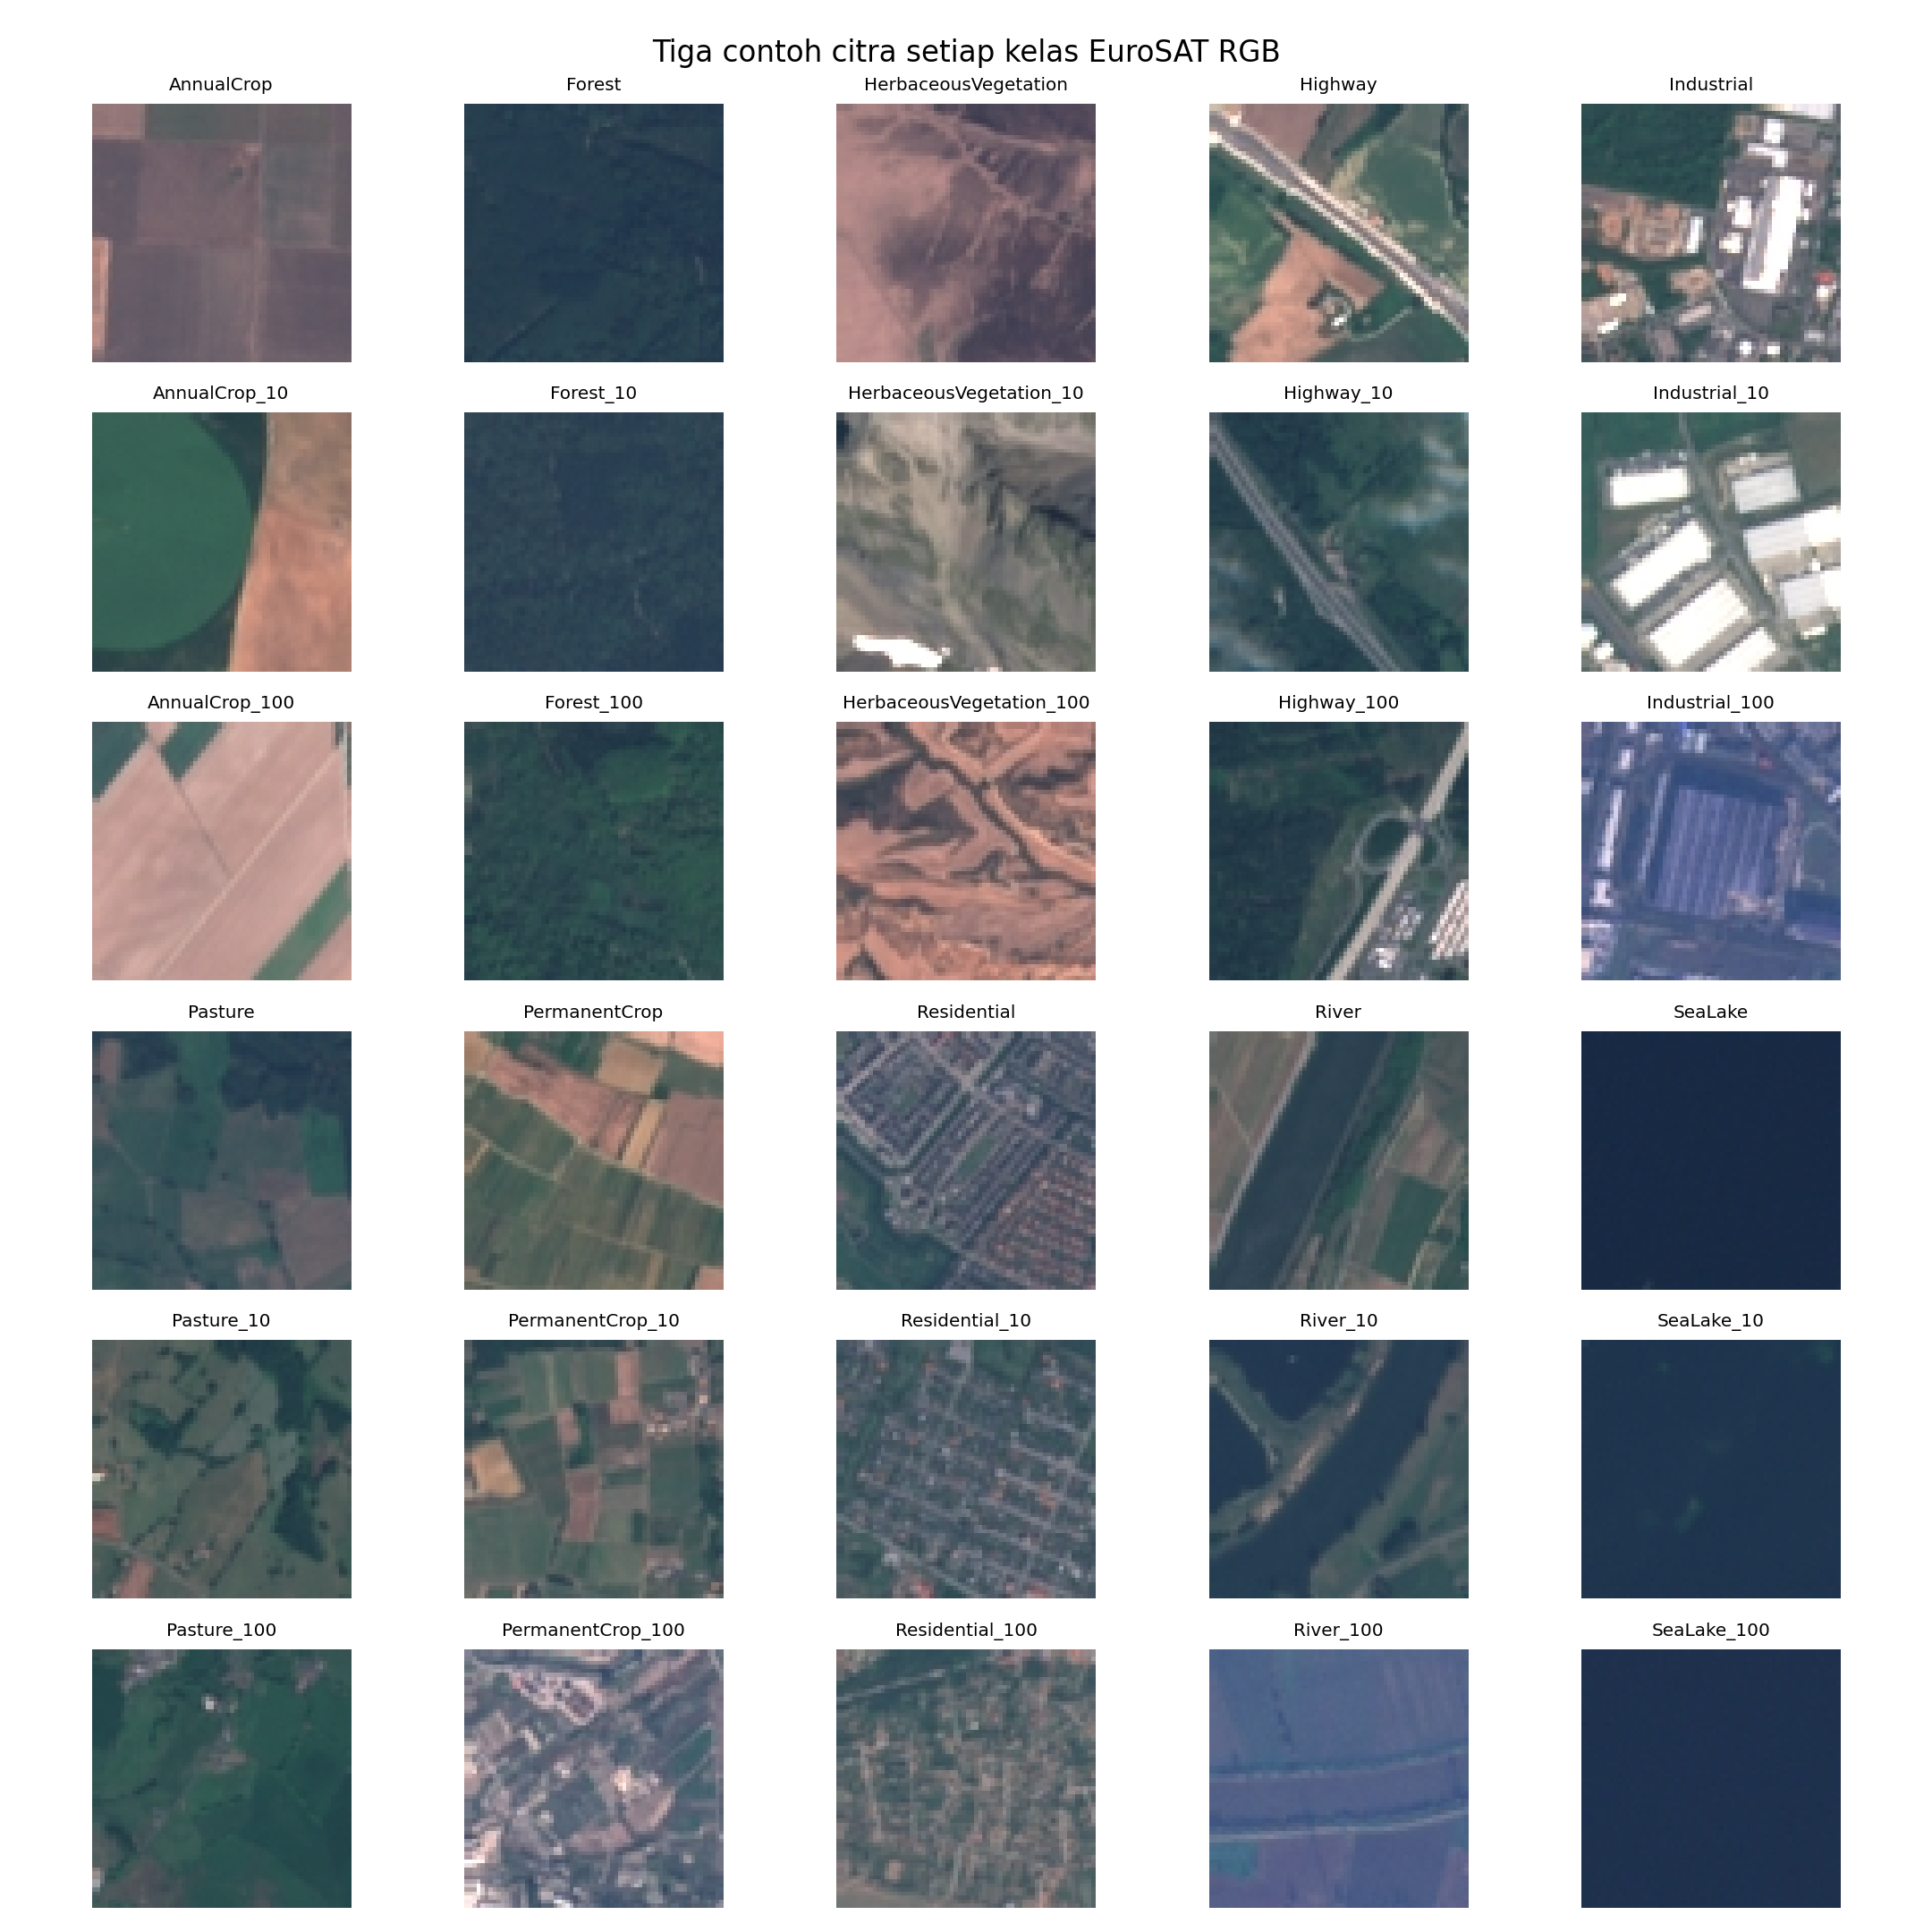

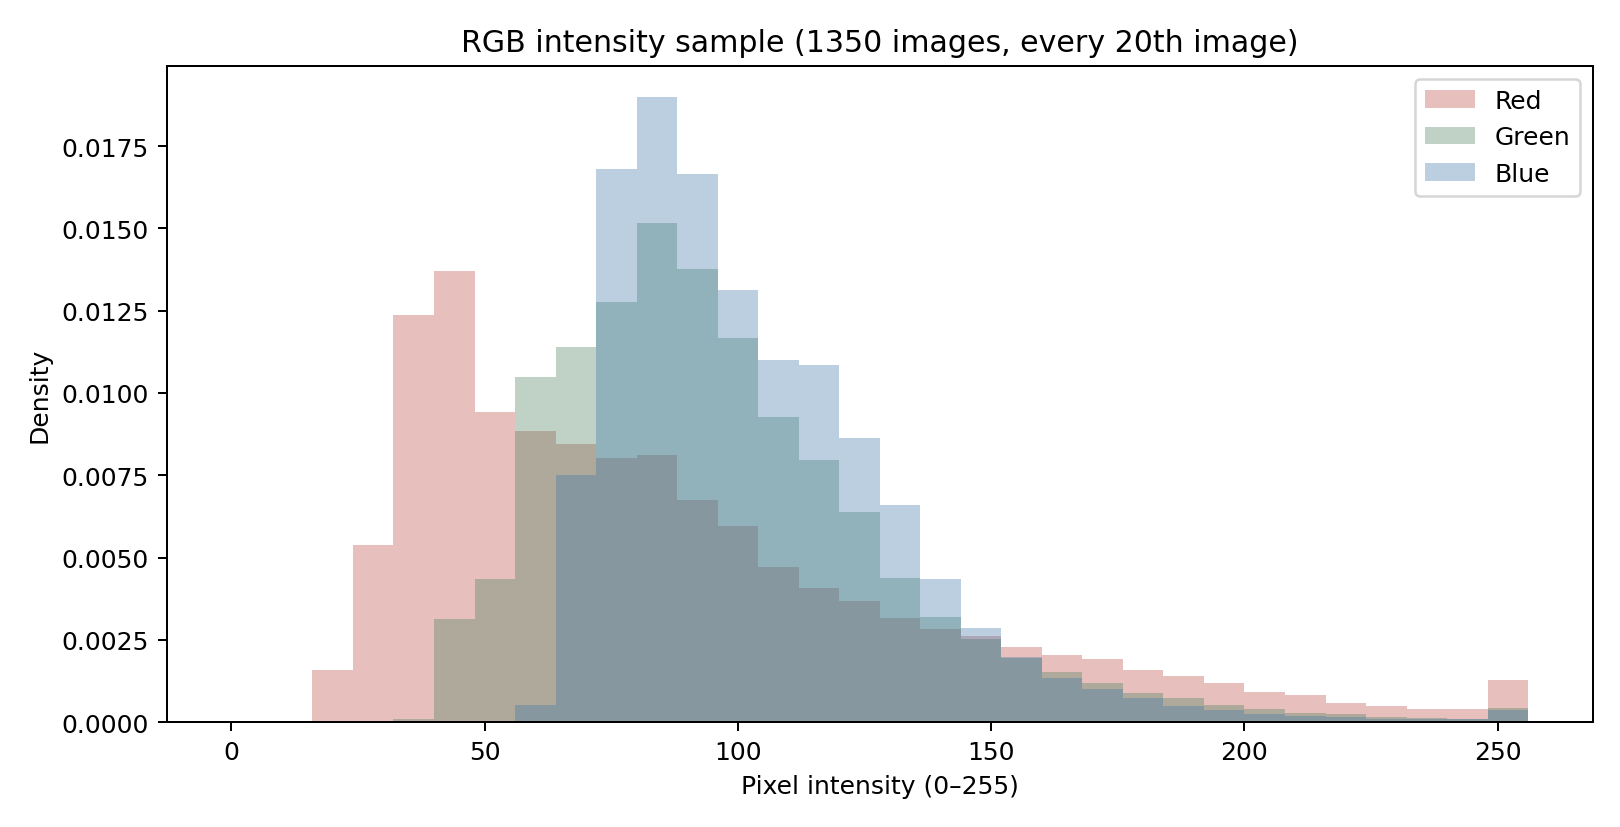

**Hasil yang Diperoleh**

Terdapat **27,000 citra**, **10 kelas**, **0 berkas rusak**, dan **0 pasangan duplikat byte-identik**. Resolusi: `{'(64, 64)': 27000}`; mode: `{'RGB': 27000}`.

**Temuan Awal**

Kelas berukuran 2,000–3,000 citra. Stratifikasi dan macro-F1 digunakan. Audit hash tidak meniadakan kemiripan atau ketergantungan geografis.

In [3]:
from src.data import prepare_archive,find_root,CLASS_NAMES
from src.analyze import audit
archive=Path('data/EuroSAT_RGB.zip')
if not archive.is_file():
    candidates=list(PROJECT.glob('*.zip'))+list(PROJECT.parent.glob('EuroSAT*.zip'))
    data_zip=None
    for candidate in candidates:
        with zipfile.ZipFile(candidate) as z:
            if sum(n.lower().endswith('.jpg') for n in z.namelist())==27000:
                data_zip=candidate;break
    if data_zip is None:
        try:from google.colab import files
        except ImportError:raise FileNotFoundError('Letakkan EuroSAT_RGB.zip pada folder data atau folder proyek.')
        print('Unggah ZIP DATASET EuroSAT RGB yang berisi 27.000 JPEG.')
        uploaded=files.upload()
        data_zip=next((Path(n) for n in uploaded if n.lower().endswith('.zip')),None)
        if data_zip is None:raise FileNotFoundError('ZIP dataset belum dipilih.')
    archive.parent.mkdir(exist_ok=True)
    if data_zip.resolve()!=archive.resolve():shutil.copy2(data_zip,archive)
if not Path('data/EuroSAT_RGB').is_dir():prepare_archive(archive,'data')
root=find_root('data')
eda=audit(root,'artifacts/eda')
assert eda['total']==27000 and len(eda['counts'])==10
assert not eda['verified_broken_files'] and not eda['sha256_exact_duplicate_pairs']
for figure in ['class_distribution','class_samples','rgb_histogram_sample']:
    display(IPImage(filename=f'artifacts/eda/{figure}.png'))
display(Markdown(f"**Hasil yang Diperoleh**\n\nTerdapat **{eda['total']:,} citra**, **{len(eda['counts'])} kelas**, **{len(eda['verified_broken_files'])} berkas rusak**, dan **{len(eda['sha256_exact_duplicate_pairs'])} pasangan duplikat byte-identik**. Resolusi: `{eda['sizes']}`; mode: `{eda['modes']}`.\n\n**Temuan Awal**\n\nKelas berukuran {min(eda['counts'].values()):,}–{max(eda['counts'].values()):,} citra. Stratifikasi dan macro-F1 digunakan. Audit hash tidak meniadakan kemiripan atau ketergantungan geografis."))


## 3 Preprocessing split dan arsitektur

Memisahkan 70% training, 15% validation, dan 15% testing. Citra tetap 64×64, piksel diubah ke float, lalu dinormalisasi dengan mean dan simpangan baku ImageNet. Flip horizontal/vertikal (p=0,5) dan rotasi ±20° hanya pada training; fill rotasi (124,116,104).


,train,val,test
AnnualCrop,2100,450,450
Forest,2100,450,450
HerbaceousVegetation,2100,450,450
Highway,1750,375,375
Industrial,1750,375,375
Pasture,1400,300,300
PermanentCrop,1750,375,375
Residential,2100,450,450
River,1750,375,375
SeaLake,2100,450,450


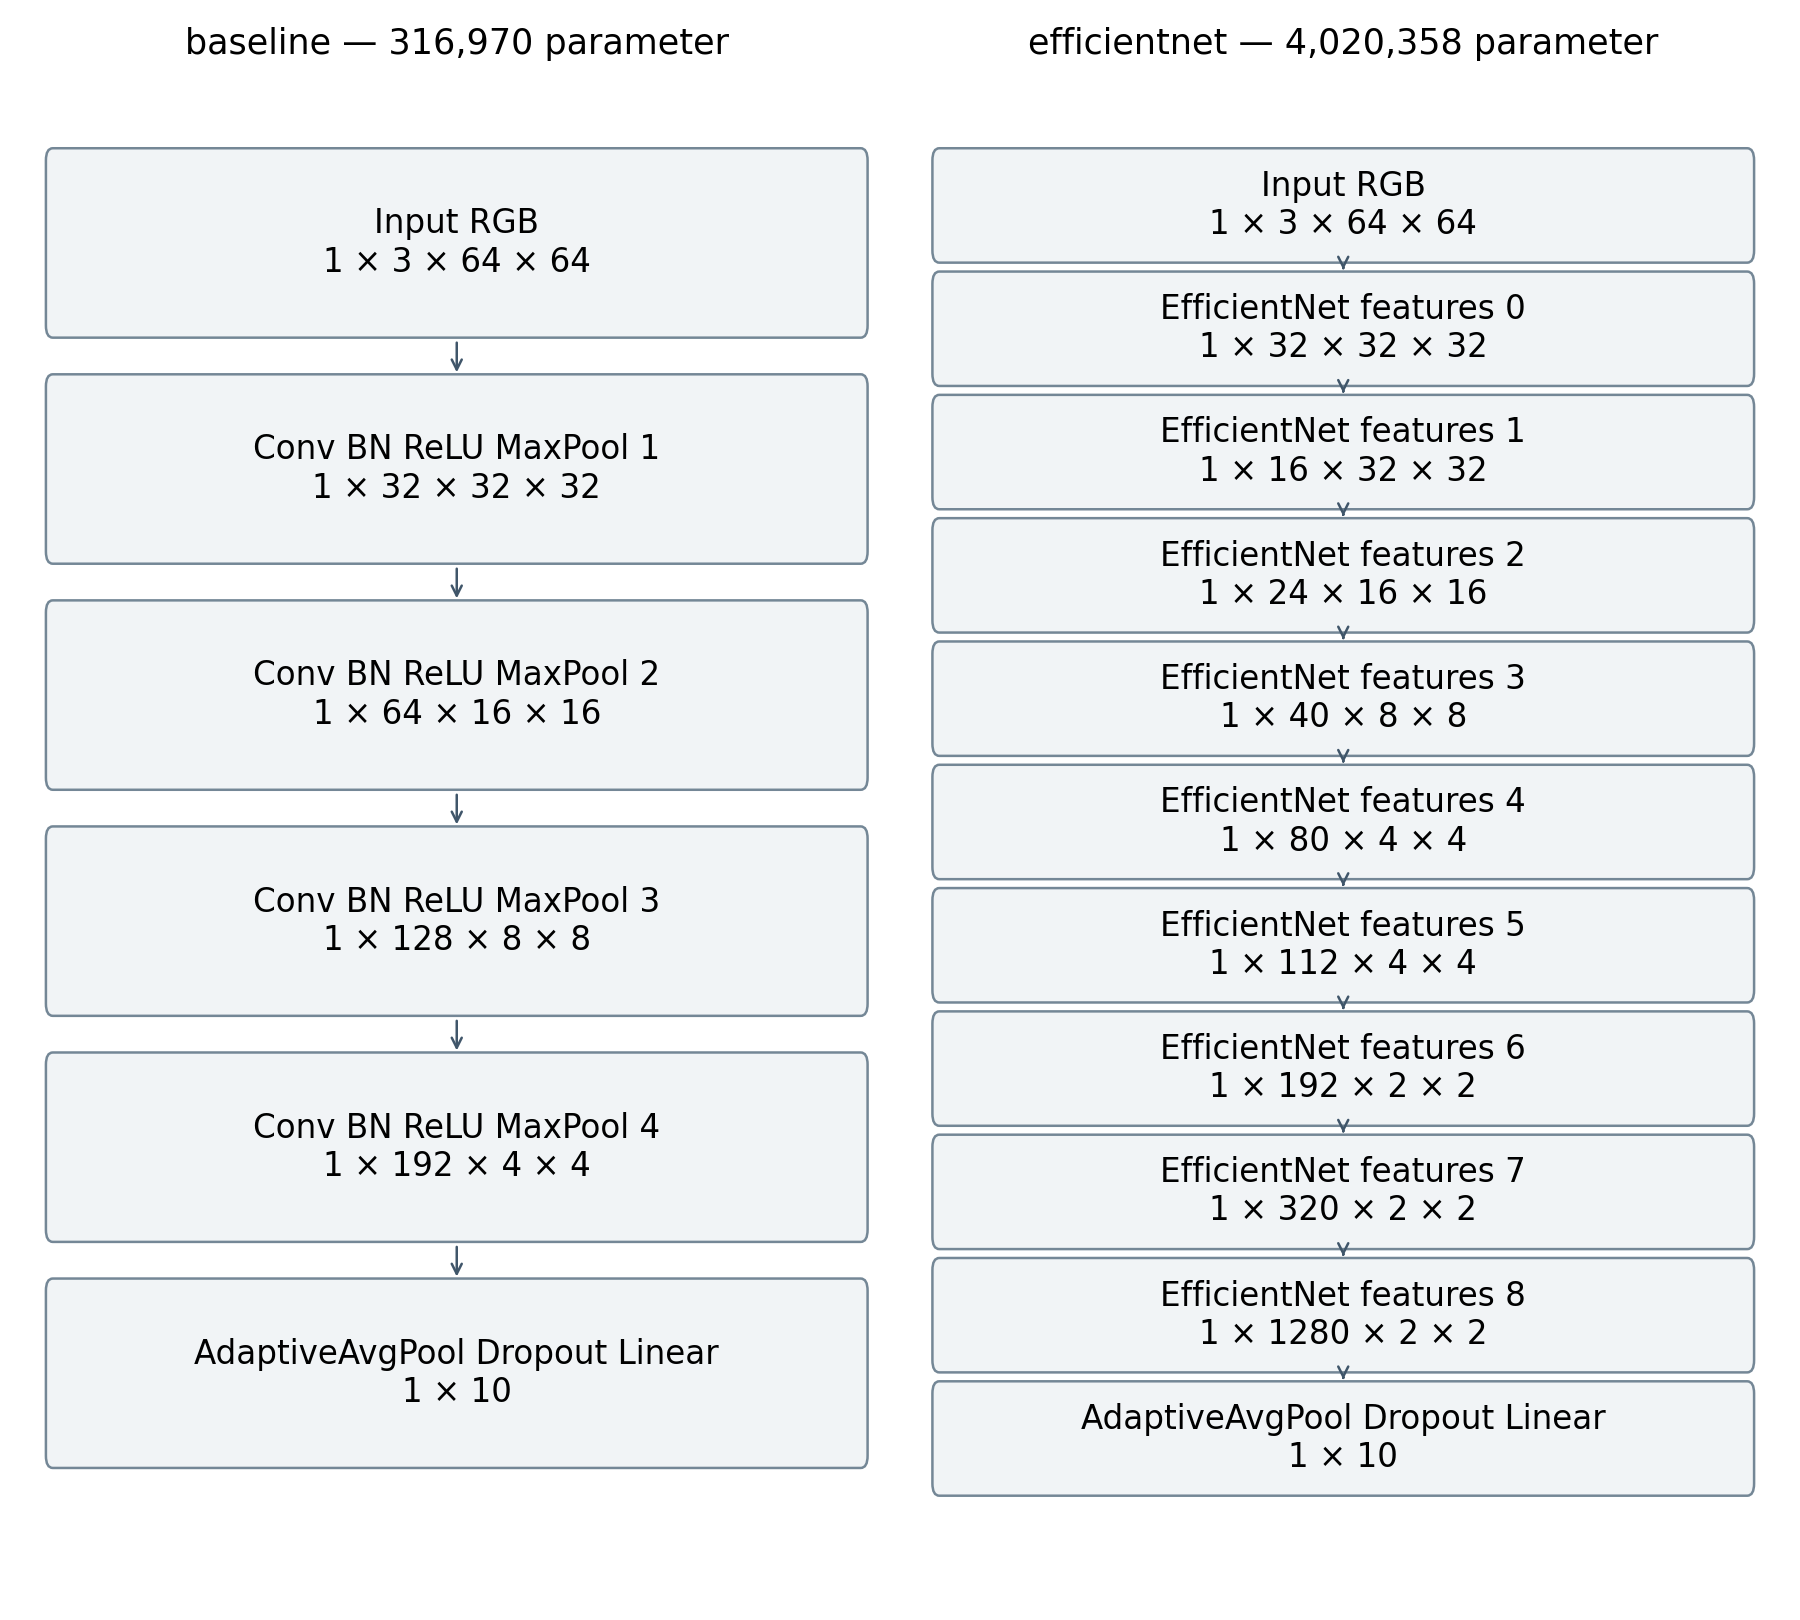

**Hasil yang Diperoleh**

Split: **18,900 train / 4,050 validation / 4,050 test**, tanpa overlap path. Parameter CNN dasar **316,970**, EfficientNet-B0 **4,020,358**.

**Temuan Awal**

Manifest memvalidasi label, path, dan fingerprint isi citra. Augmentasi tidak diterapkan pada validation/test. Split acak ini belum membuktikan generalisasi lintas wilayah.

In [4]:
from src.data import make_manifest,transform
manifest=make_manifest(root,'artifacts/eksperimen/split_manifest.json')
counts=pd.DataFrame({part:{name:sum(x['label']==i for x in manifest[part]) for i,name in enumerate(CLASS_NAMES)} for part in ['train','val','test']})
display(counts)
assert tuple(len(manifest[s]) for s in ['train','val','test'])==(18900,4050,4050)
subprocess.run([sys.executable,'scripts/make_architecture.py'],check=True,capture_output=True)
architecture=json.loads(Path('artifacts/eda/architecture_details.json').read_text())
display(IPImage(filename='artifacts/eda/architecture_diagram.png'))
display(Markdown(f"**Hasil yang Diperoleh**\n\nSplit: **{len(manifest['train']):,} train / {len(manifest['val']):,} validation / {len(manifest['test']):,} test**, tanpa overlap path. Parameter CNN dasar **{architecture['baseline']['total_parameters']:,}**, EfficientNet-B0 **{architecture['efficientnet']['total_parameters']:,}**.\n\n**Temuan Awal**\n\nManifest memvalidasi label, path, dan fingerprint isi citra. Augmentasi tidak diterapkan pada validation/test. Split acak ini belum membuktikan generalisasi lintas wilayah."))


## 4 CNN dasar sebagai baseline

Melatih empat blok Conv2D–BatchNorm–ReLU–MaxPool, global average pooling, dropout 0,3, dan Linear 10. AdamW, learning rate 5×10⁻⁴, maksimal 8 epoch, patience 4; pemilihan berdasarkan macro-F1 validasi.


Use existing validated training output: baseline



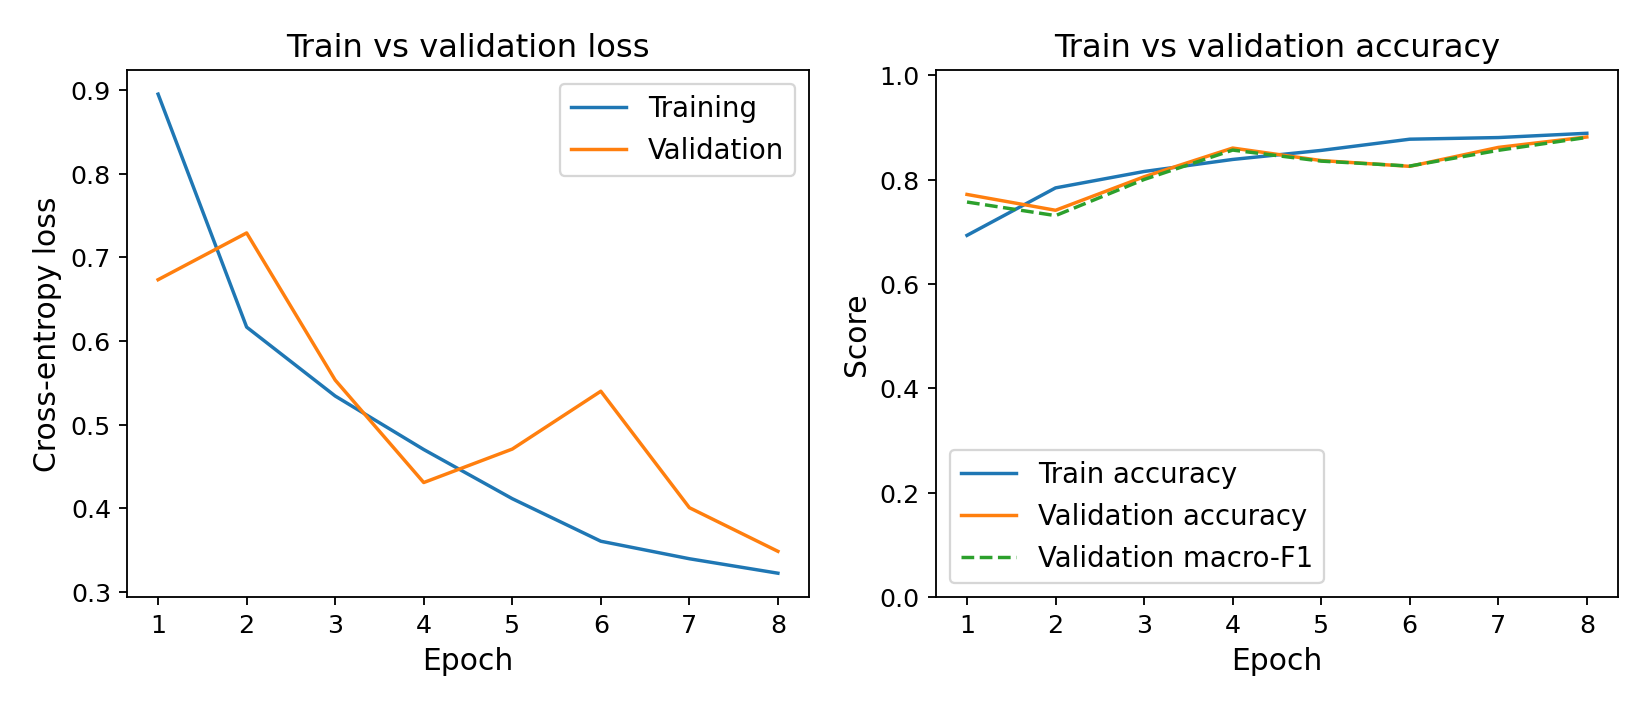

**Hasil yang Diperoleh**

Baseline dilatih pada **18,900** citra selama **8 epoch**; checkpoint epoch **8** memperoleh validation accuracy **88.1975%** dan macro-F1 **0.8811**.

**Temuan Awal**

Model ini menjadi pembanding yang memakai split dan preprocessing sama. Selisih kurva train–validation perlu ditinjau sebelum menyimpulkan overfitting.

In [5]:
run_stage('baseline')
base_val=json.loads(Path('artifacts/eksperimen/baseline/validation_results.json').read_text())
display(IPImage(filename='artifacts/eksperimen/baseline/learning_curves.png'))
display(Markdown(f"**Hasil yang Diperoleh**\n\nBaseline dilatih pada **{base_val['train_samples']:,}** citra selama **{len(base_val['history']['train_loss'])} epoch**; checkpoint epoch **{base_val['best_epoch']}** memperoleh validation accuracy **{base_val['validation_metrics']['accuracy']:.4%}** dan macro-F1 **{base_val['validation_metrics']['macro_f1']:.4f}**.\n\n**Temuan Awal**\n\nModel ini menjadi pembanding yang memakai split dan preprocessing sama. Selisih kurva train–validation perlu ditinjau sebelum menyimpulkan overfitting."))


## 5 EfficientNet B0 tahap feature extraction

Mengunduh bobot ImageNet resmi, membekukan backbone beserta statistik BatchNorm, dan melatih head 10 kelas dengan AdamW LR 10⁻³, maksimal 5 epoch, patience 3. Tidak menggunakan hasil test.


Use existing validated training output: head



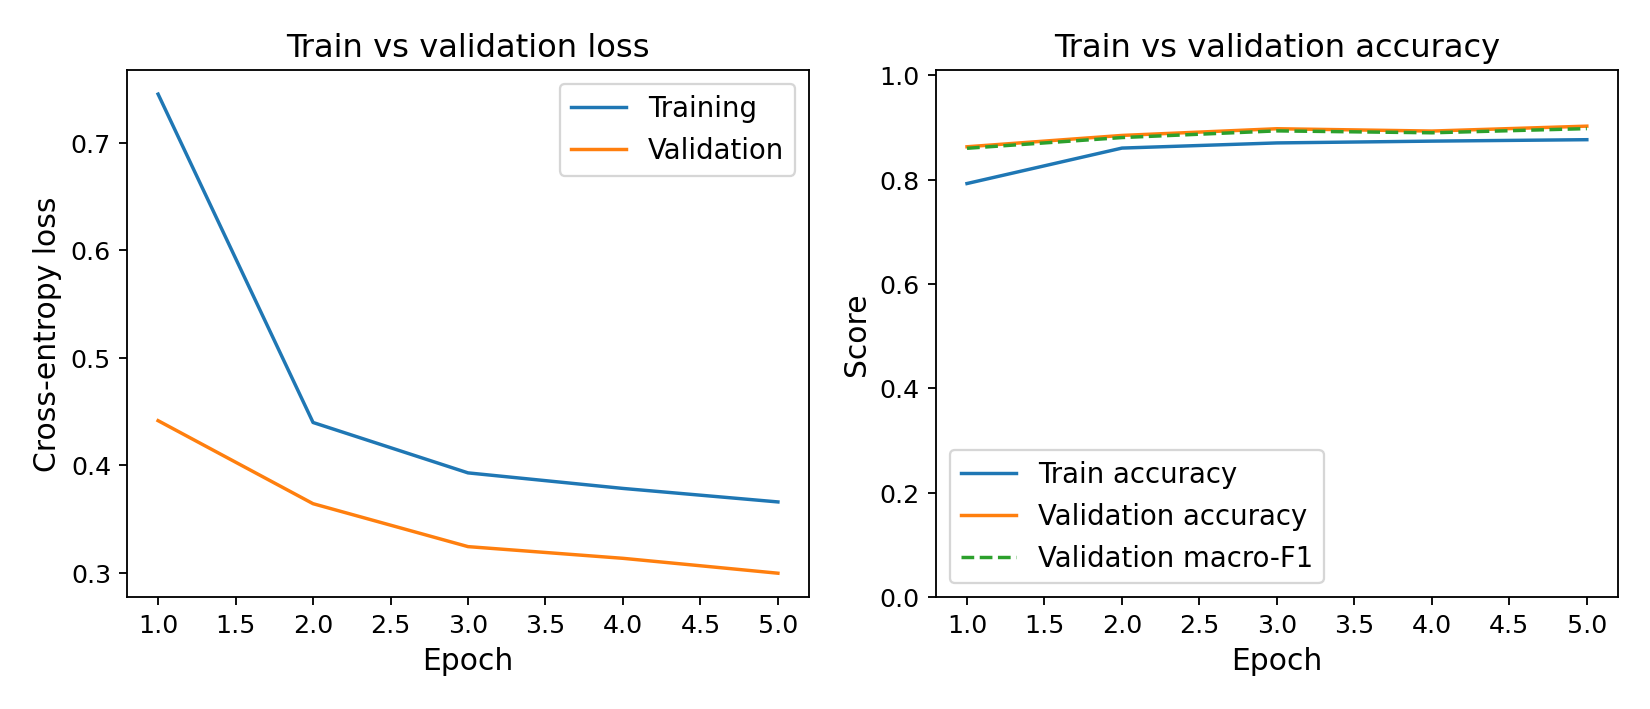

**Hasil yang Diperoleh**

Feature extraction memakai **12,810 parameter trainable** dari **4,020,358 parameter**. Validation accuracy **90.2716%**, macro-F1 **0.8980**, checkpoint epoch **5**.

**Temuan Awal**

Backbone tetap menggunakan fitur ImageNet. Seluruh citra training digunakan; tidak ada penggantian bobot pralatih dengan bobot acak.

In [6]:
run_stage('head')
head_val=json.loads(Path('artifacts/stage1/efficientnet/validation_results.json').read_text())
display(IPImage(filename='artifacts/stage1/efficientnet/learning_curves.png'))
display(Markdown(f"**Hasil yang Diperoleh**\n\nFeature extraction memakai **{head_val['trainable_params']:,} parameter trainable** dari **{head_val['params']:,} parameter**. Validation accuracy **{head_val['validation_metrics']['accuracy']:.4%}**, macro-F1 **{head_val['validation_metrics']['macro_f1']:.4f}**, checkpoint epoch **{head_val['best_epoch']}**.\n\n**Temuan Awal**\n\nBackbone tetap menggunakan fitur ImageNet. Seluruh citra training digunakan; tidak ada penggantian bobot pralatih dengan bobot acak."))


## 6 Fine tuning dan penguncian checkpoint

Melanjutkan bobot tahap head, membuka seluruh backbone, dan memakai LR 5×10⁻⁵, maksimal 8 epoch, patience 4. Bobot tahap head dipertahankan apabila tidak ada peningkatan macro-F1 validasi.


Use existing validated training output: finetune



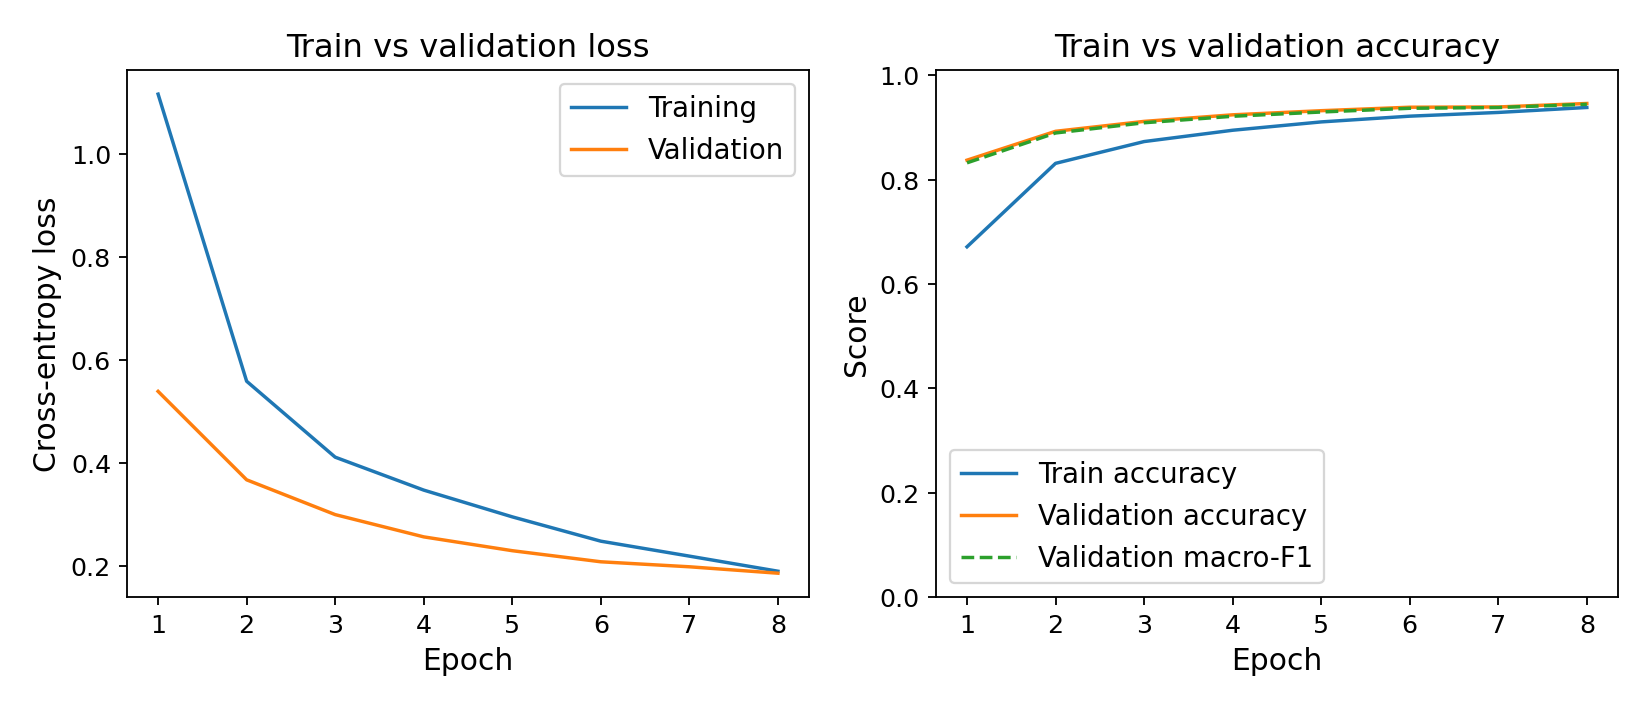

**Hasil yang Diperoleh**

Checkpoint akhir epoch **8** memperoleh validation accuracy **94.6173%**, macro-F1 **0.9446**, dan Δ macro-F1 terhadap head **+0.0467**.

**Temuan Awal**

Epoch 0 berarti bobot tahap head tetap terbaik. Pemilihan bobot didasarkan pada validation, kemudian dikunci sebelum test.

In [7]:
run_stage('finetune')
eff_val=json.loads(Path('artifacts/eksperimen/efficientnet/validation_results.json').read_text())
display(IPImage(filename='artifacts/eksperimen/efficientnet/learning_curves.png'))
delta_val=eff_val['validation_metrics']['macro_f1']-head_val['validation_metrics']['macro_f1']
display(Markdown(f"**Hasil yang Diperoleh**\n\nCheckpoint akhir epoch **{eff_val['best_epoch']}** memperoleh validation accuracy **{eff_val['validation_metrics']['accuracy']:.4%}**, macro-F1 **{eff_val['validation_metrics']['macro_f1']:.4f}**, dan Δ macro-F1 terhadap head **{delta_val:+.4f}**.\n\n**Temuan Awal**\n\nEpoch 0 berarti bobot tahap head tetap terbaik. Pemilihan bobot didasarkan pada validation, kemudian dikunci sebelum test."))


## 7 Kalibrasi validasi dan evaluasi holdout

Menetapkan threshold dari validation dengan coverage minimum 70% sebelum membuka test. Setelah itu menghitung metrik kedua checkpoint terpilih pada 4.050 citra testing. Ambang tidak diubah berdasarkan hasil testing.


baseline: using saved final test results; no reevaluation
efficientnet: using saved final test results; no reevaluation


,Model,N_test,loss,accuracy,macro_precision,macro_recall,macro_f1
0,baseline,4050,0.345171,0.880741,0.892780,0.878911,0.880688
1,efficientnet,4050,0.170720,0.943951,0.944394,0.942467,0.943149


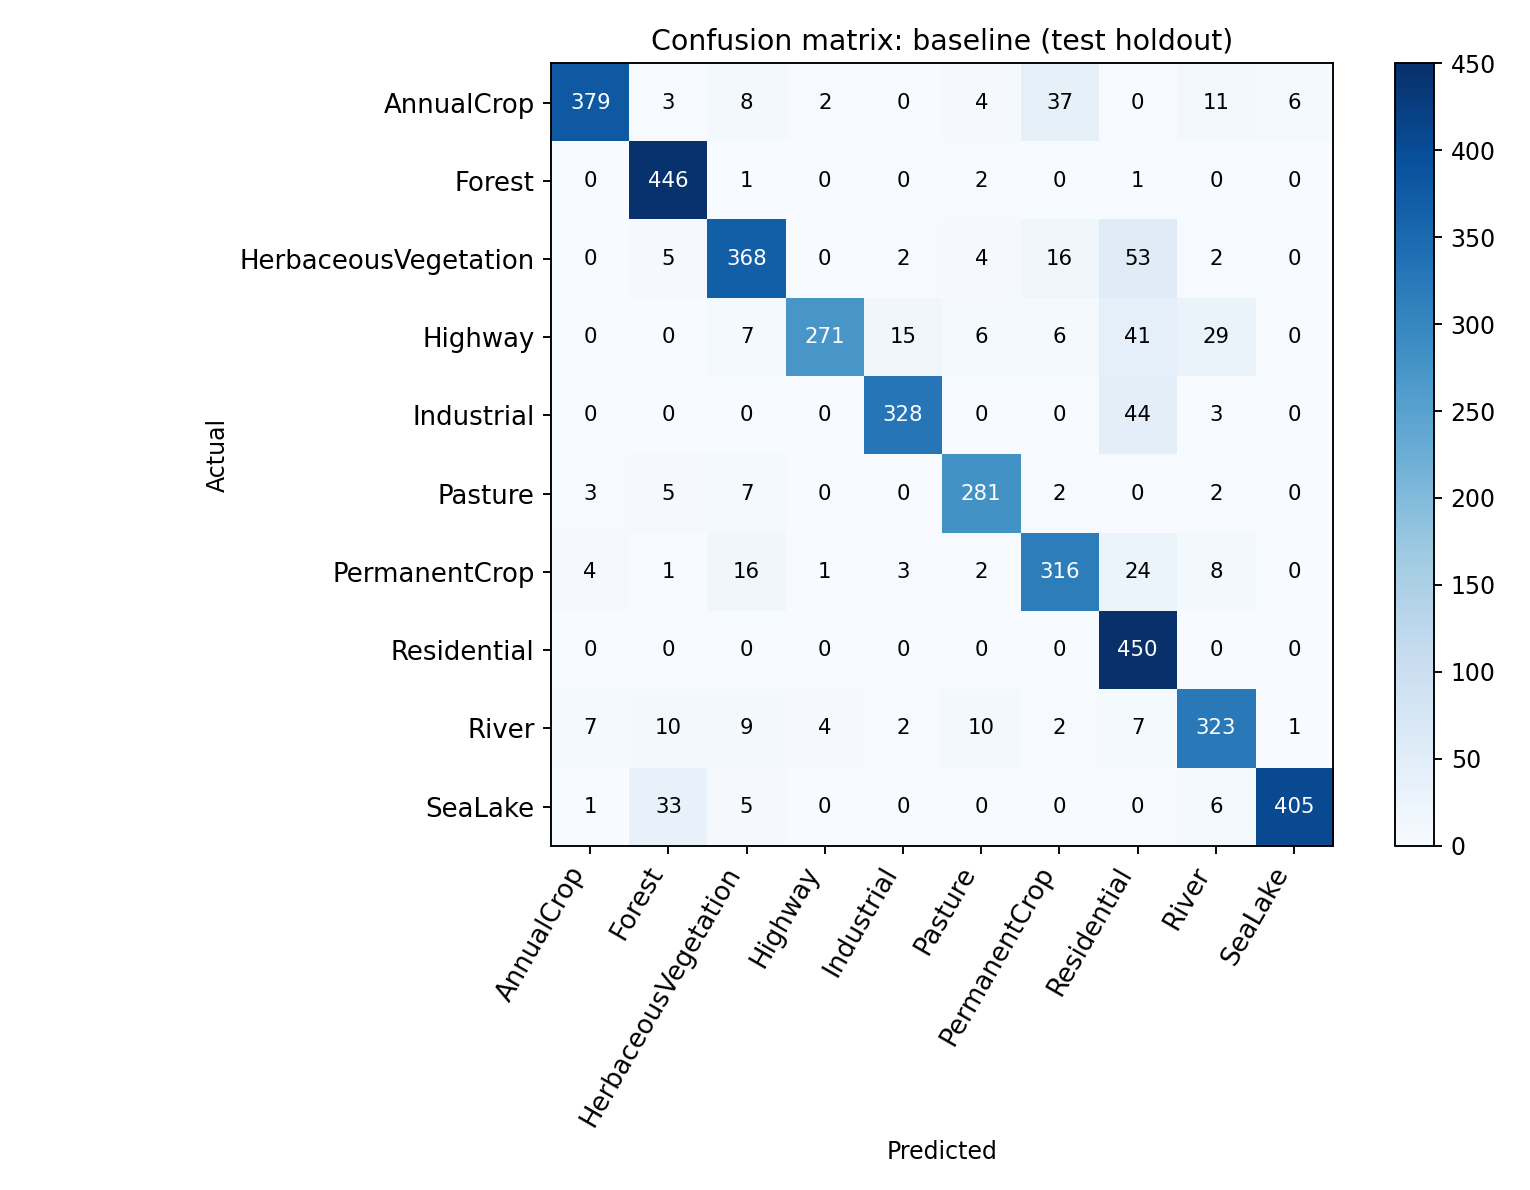

,precision,recall,f1-score,support
AnnualCrop,0.961929,0.842222,0.898104,450.0
Forest,0.886680,0.991111,0.935992,450.0
HerbaceousVegetation,0.874109,0.817778,0.845006,450.0
Highway,0.974820,0.722667,0.830015,375.0
Industrial,0.937143,0.874667,0.904828,375.0
Pasture,0.909385,0.936667,0.922824,300.0
PermanentCrop,0.833773,0.842667,0.838196,375.0
Residential,0.725806,1.000000,0.841121,450.0
River,0.841146,0.861333,0.851120,375.0
SeaLake,0.983010,0.900000,0.939675,450.0


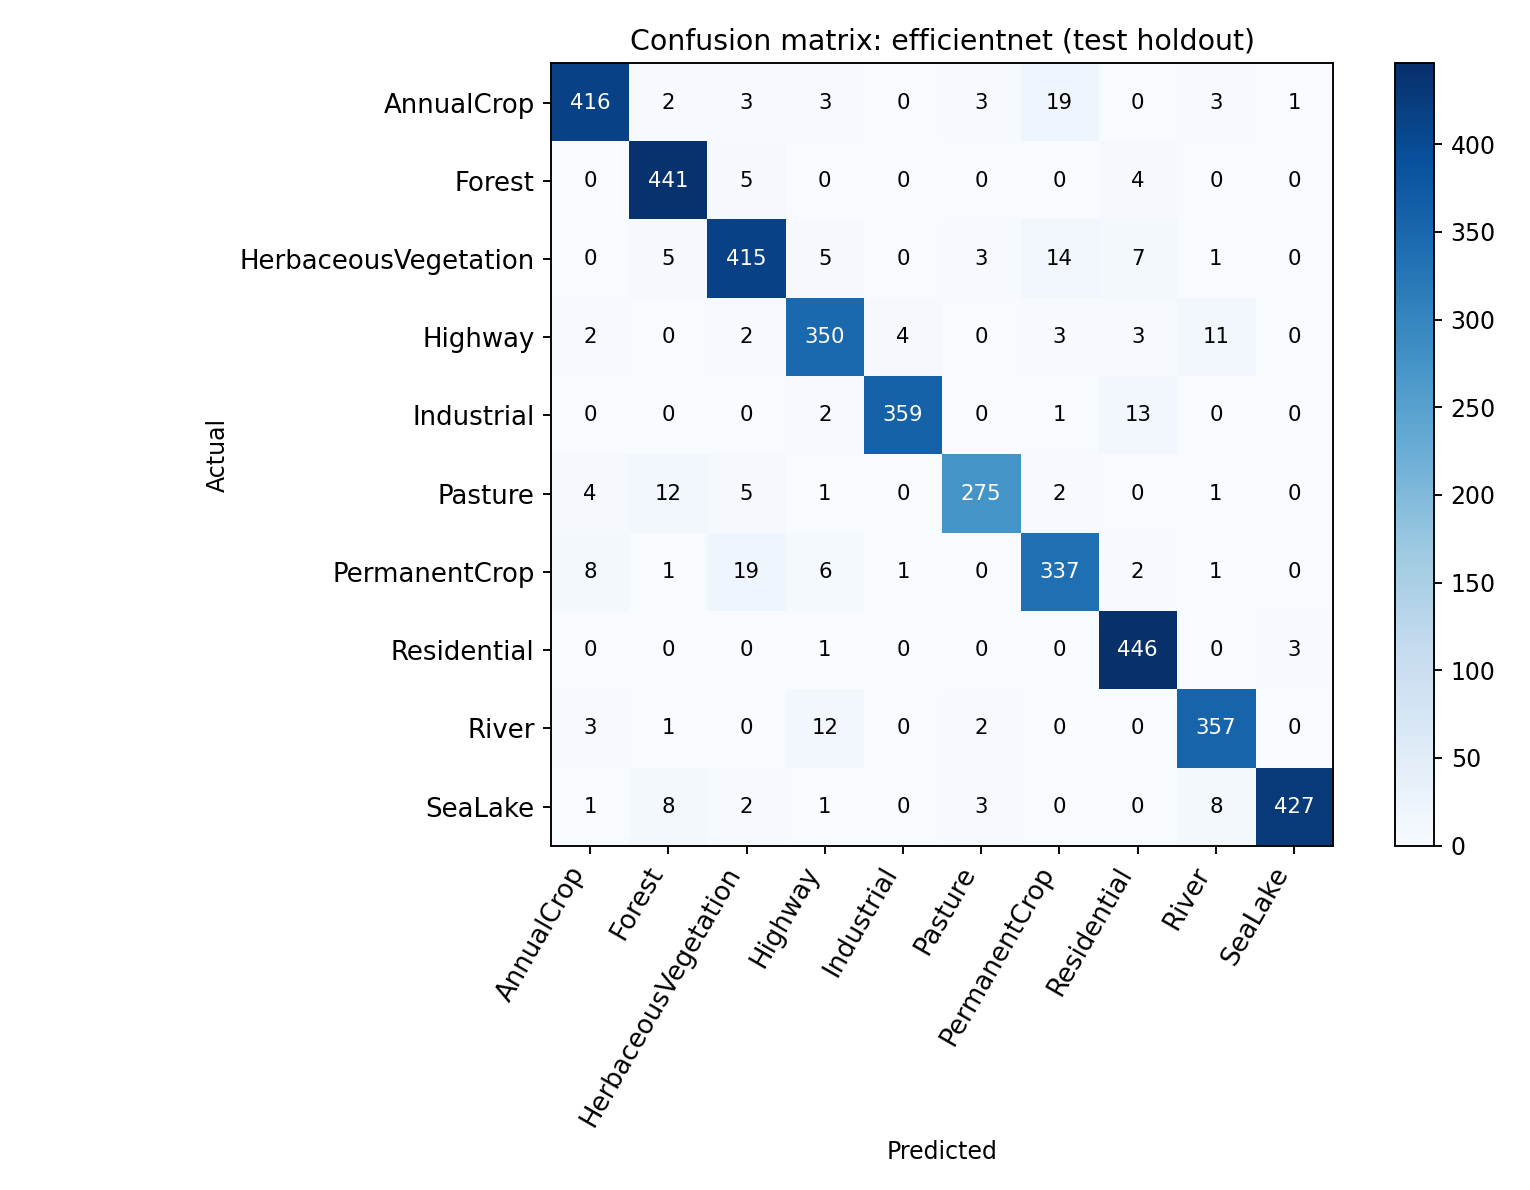

,precision,recall,f1-score,support
AnnualCrop,0.958525,0.924444,0.941176,450.0
Forest,0.938298,0.980000,0.958696,450.0
HerbaceousVegetation,0.920177,0.922222,0.921199,450.0
Highway,0.918635,0.933333,0.925926,375.0
Industrial,0.986264,0.957333,0.971583,375.0
Pasture,0.961538,0.916667,0.938567,300.0
PermanentCrop,0.896277,0.898667,0.897470,375.0
Residential,0.938947,0.991111,0.964324,450.0
River,0.934555,0.952000,0.943197,375.0
SeaLake,0.990719,0.948889,0.969353,450.0


**Hasil yang Diperoleh**

Masing-masing model diuji pada **4,050** citra. Baseline accuracy **88.0741%**, macro-F1 **0.8807**; EfficientNet accuracy **94.3951%**, macro-F1 **0.9431**.

**Temuan Awal**

Ambang **0.992040** telah dikunci pada validation. Pembacaan ulang hasil tersimpan tidak melakukan tuning atau evaluasi test ulang.

In [8]:
from src.threshold import calibrate
calibration=calibrate('artifacts/eksperimen/efficientnet',cfg['threshold_minimum_coverage'])
from src.finalize import finalize
finalize('.',root,cfg['batch_size'],cfg['workers'])
base=json.loads(Path('artifacts/eksperimen/baseline/results.json').read_text())
eff=json.loads(Path('artifacts/eksperimen/efficientnet/results.json').read_text())
metrics=pd.DataFrame([{'Model':r['model'],'N_test':r['test_samples'],**r['test_metrics']} for r in [base,eff]])
display(metrics)
for name,r in [('baseline',base),('efficientnet',eff)]:
    display(IPImage(filename=f'artifacts/eksperimen/{name}/confusion_matrix.png'))
    per_class=pd.DataFrame(r['classification_report']).T.loc[CLASS_NAMES,['precision','recall','f1-score','support']]
    display(per_class)
display(Markdown(f"**Hasil yang Diperoleh**\n\nMasing-masing model diuji pada **{eff['test_samples']:,}** citra. Baseline accuracy **{base['test_metrics']['accuracy']:.4%}**, macro-F1 **{base['test_metrics']['macro_f1']:.4f}**; EfficientNet accuracy **{eff['test_metrics']['accuracy']:.4%}**, macro-F1 **{eff['test_metrics']['macro_f1']:.4f}**.\n\n**Temuan Awal**\n\nAmbang **{calibration['threshold']:.6f}** telah dikunci pada validation. Pembacaan ulang hasil tersimpan tidak melakukan tuning atau evaluasi test ulang."))


## 8 Interpretasi Grad CAM

Menampilkan contoh prediksi benar dan salah dari holdout. Grad-CAM menggunakan gradien kelas prediksi pada konvolusi terakhir, bukan ground truth segmentasi, serta tidak mengubah label prediksi.


Benar: asli=Residential; prediksi=Residential; confidence=0.9950
Salah: asli=HerbaceousVegetation; prediksi=Highway; confidence=0.9991


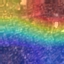

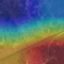

**Hasil yang Diperoleh**

Terdapat **3,823** prediksi benar dan **227** prediksi salah. Contoh Grad-CAM dipilih dari hasil asli tersebut.

**Temuan Awal**

Peta perhatian bersifat kasar karena feature map akhir hanya 2×2 pada input 64×64; overlay yang diperbesar tidak menambah ketelitian lokalisasi. Tidak ada klaim peningkatan accuracy karena Grad-CAM.

In [9]:
from src.infer import Predictor
from PIL import Image as PILImage
predictor=Predictor('artifacts/eksperimen/efficientnet/best.pt')
with np.load('artifacts/eksperimen/efficientnet/probabilities.npz') as p:
    test_y=p['test_y'];test_prob=p['test_probs'];test_pred=test_prob.argmax(1)
correct=np.flatnonzero(test_y==test_pred);wrong=np.flatnonzero(test_y!=test_pred)
for label,indices in [('Benar',correct),('Salah',wrong)]:
    if not len(indices):print(f'Tidak ada contoh {label.lower()} di hasil test.');continue
    idx=int(indices[0]);entry=manifest['test'][idx]
    with PILImage.open(root/entry['path']) as im:res=predictor.predict(im)
    print(f"{label}: asli={CLASS_NAMES[entry['label']]}; prediksi={res['label']}; confidence={res['confidence']:.4f}")
    display(res['gradcam'])
display(Markdown(f"**Hasil yang Diperoleh**\n\nTerdapat **{len(correct):,}** prediksi benar dan **{len(wrong):,}** prediksi salah. Contoh Grad-CAM dipilih dari hasil asli tersebut.\n\n**Temuan Awal**\n\nPeta perhatian bersifat kasar karena feature map akhir hanya 2×2 pada input 64×64; overlay yang diperbesar tidak menambah ketelitian lokalisasi. Tidak ada klaim peningkatan accuracy karena Grad-CAM."))


## 9 Confidence threshold sebelum dan sesudah penolakan

Membandingkan semua prediksi dengan prediksi yang diterima oleh ambang validasi. Coverage minimum 70% merupakan syarat pemilihan pada validation, bukan jaminan coverage test. Confidence softmax belum tentu terkalibrasi.


,Skenario,threshold,coverage,selective_accuracy,overall_accuracy,accepted,rejected,rejected_errors,rejected_correct
0,Tanpa penolakan,0.00000,1.000000,0.943951,0.943951,4050,0,0,0
1,Dengan threshold,0.99204,0.697531,0.996106,0.943951,2825,1225,216,1009


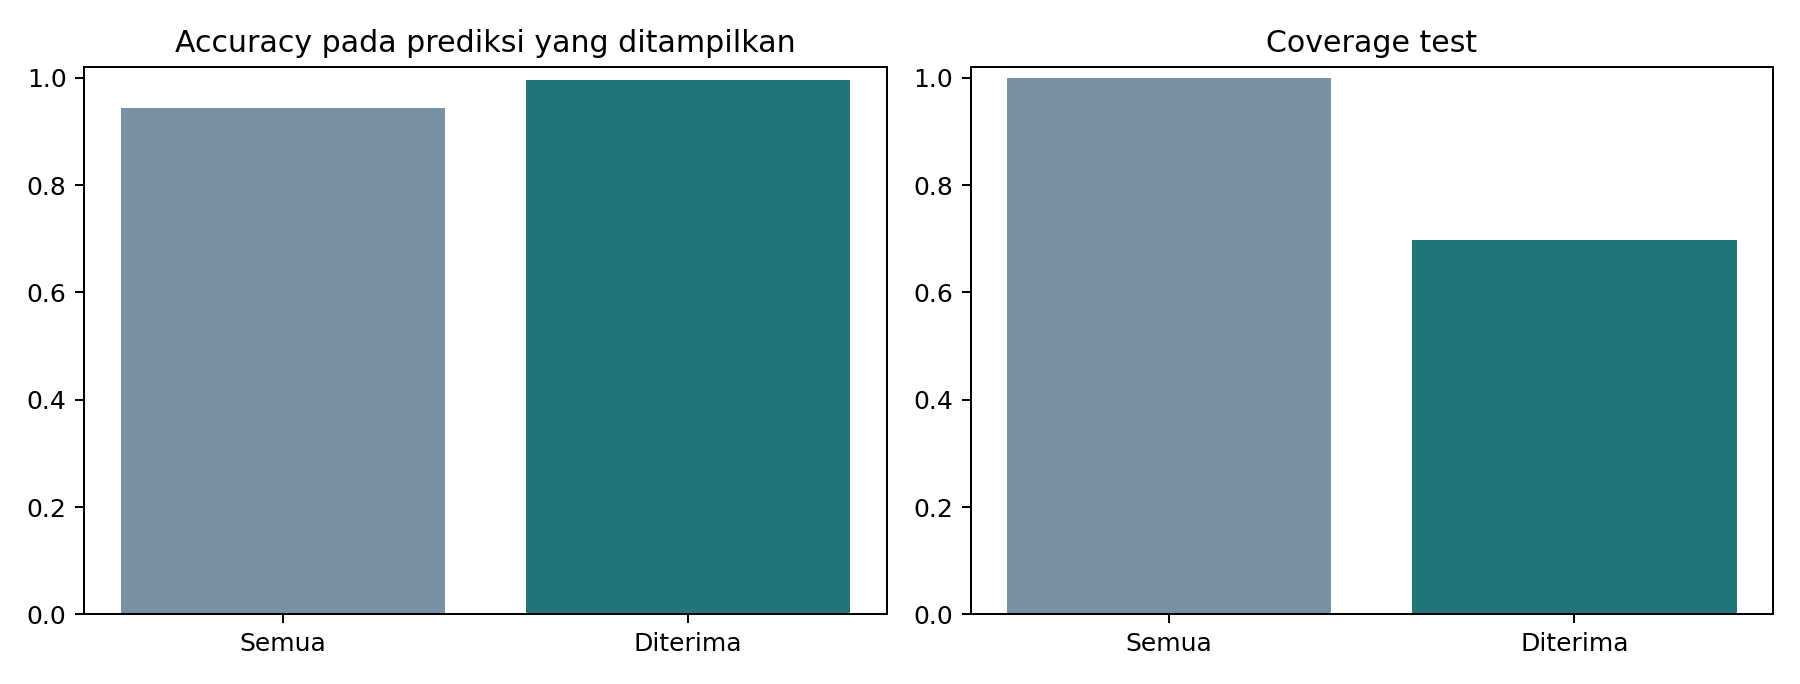

**Hasil yang Diperoleh**

Ambang **0.992040**; validation coverage **70.3210%**. Test: **2,825 diterima**, **1,225 ditolak**, coverage **69.7531%**, selective accuracy **99.6106%**, dan **216 kesalahan ditolak**.

**Temuan Awal**

Accuracy seluruh test tetap **94.3951%**. Selective accuracy memakai denominator prediksi diterima, sehingga wajib dibaca bersama coverage dan jumlah penolakan.

In [10]:
from src.threshold import run as threshold_run
threshold=threshold_run('artifacts/eksperimen/efficientnet',cfg['threshold_minimum_coverage'])
before=threshold['baseline_without_rejection'];after=threshold['test_metrics']
display(pd.DataFrame([{'Skenario':'Tanpa penolakan',**before},{'Skenario':'Dengan threshold',**after}]))
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(10,3.8))
axes[0].bar(['Semua','Diterima'],[before['selective_accuracy'],after['selective_accuracy']],color=['#7891a5','#217678'])
axes[0].set(title='Accuracy pada prediksi yang ditampilkan',ylim=(0,1.02))
axes[1].bar(['Semua','Diterima'],[before['coverage'],after['coverage']],color=['#7891a5','#217678'])
axes[1].set(title='Coverage test',ylim=(0,1.02));fig.tight_layout()
fig.savefig('artifacts/eksperimen/threshold_comparison.png',dpi=180);plt.close(fig)
display(IPImage(filename='artifacts/eksperimen/threshold_comparison.png'))
sa='tidak tersedia' if after['selective_accuracy'] is None else f"{after['selective_accuracy']:.4%}"
display(Markdown(f"**Hasil yang Diperoleh**\n\nAmbang **{threshold['threshold']:.6f}**; validation coverage **{threshold['validation_coverage']:.4%}**. Test: **{after['accepted']:,} diterima**, **{after['rejected']:,} ditolak**, coverage **{after['coverage']:.4%}**, selective accuracy **{sa}**, dan **{after['rejected_errors']:,} kesalahan ditolak**.\n\n**Temuan Awal**\n\nAccuracy seluruh test tetap **{before['overall_accuracy']:.4%}**. Selective accuracy memakai denominator prediksi diterima, sehingga wajib dibaca bersama coverage dan jumlah penolakan."))


## 10 Kesimpulan hasil dan ekspor model

Merangkum perbandingan model, Grad-CAM, dan confidence threshold, kemudian mengekspor aplikasi dengan checkpoint yang sama.

{
  "baseline_accuracy": 0.8807407407407407,
  "efficientnet_accuracy": 0.9439506172839506,
  "baseline_macro_f1": 0.8806881664075978,
  "efficientnet_macro_f1": 0.9431490692111005,
  "threshold": {
    "threshold": 0.99204021692276,
    "validation_selective_accuracy": 0.9940308988764045,
    "validation_coverage": 0.7032098765432099,
    "minimum_coverage": 0.7,
    "checkpoint_sha256": "313873f1c1a8be382afa8e60a85047effdac4ab214f3037727f158d954bb6b85",
    "selection_split": "validation",
    "split_manifest_sha256": "3ba6a3aaefdfba8b67e713454a0f10ca012ea8c8b9fc7a543db93a1efd20b1dc",
    "selected_before_test": true,
    "test_metrics": {
      "threshold": 0.99204021692276,
      "coverage": 0.6975308641975309,
      "selective_accuracy": 0.9961061946902655,
      "overall_accuracy": 0.9439506172839506,
      "accepted": 2825,
      "rejected": 1225,
      "rejected_errors": 216,
      "rejected_correct": 1009
    },
    "baseline_without_rejection": {
      "threshold": 0.0,
     

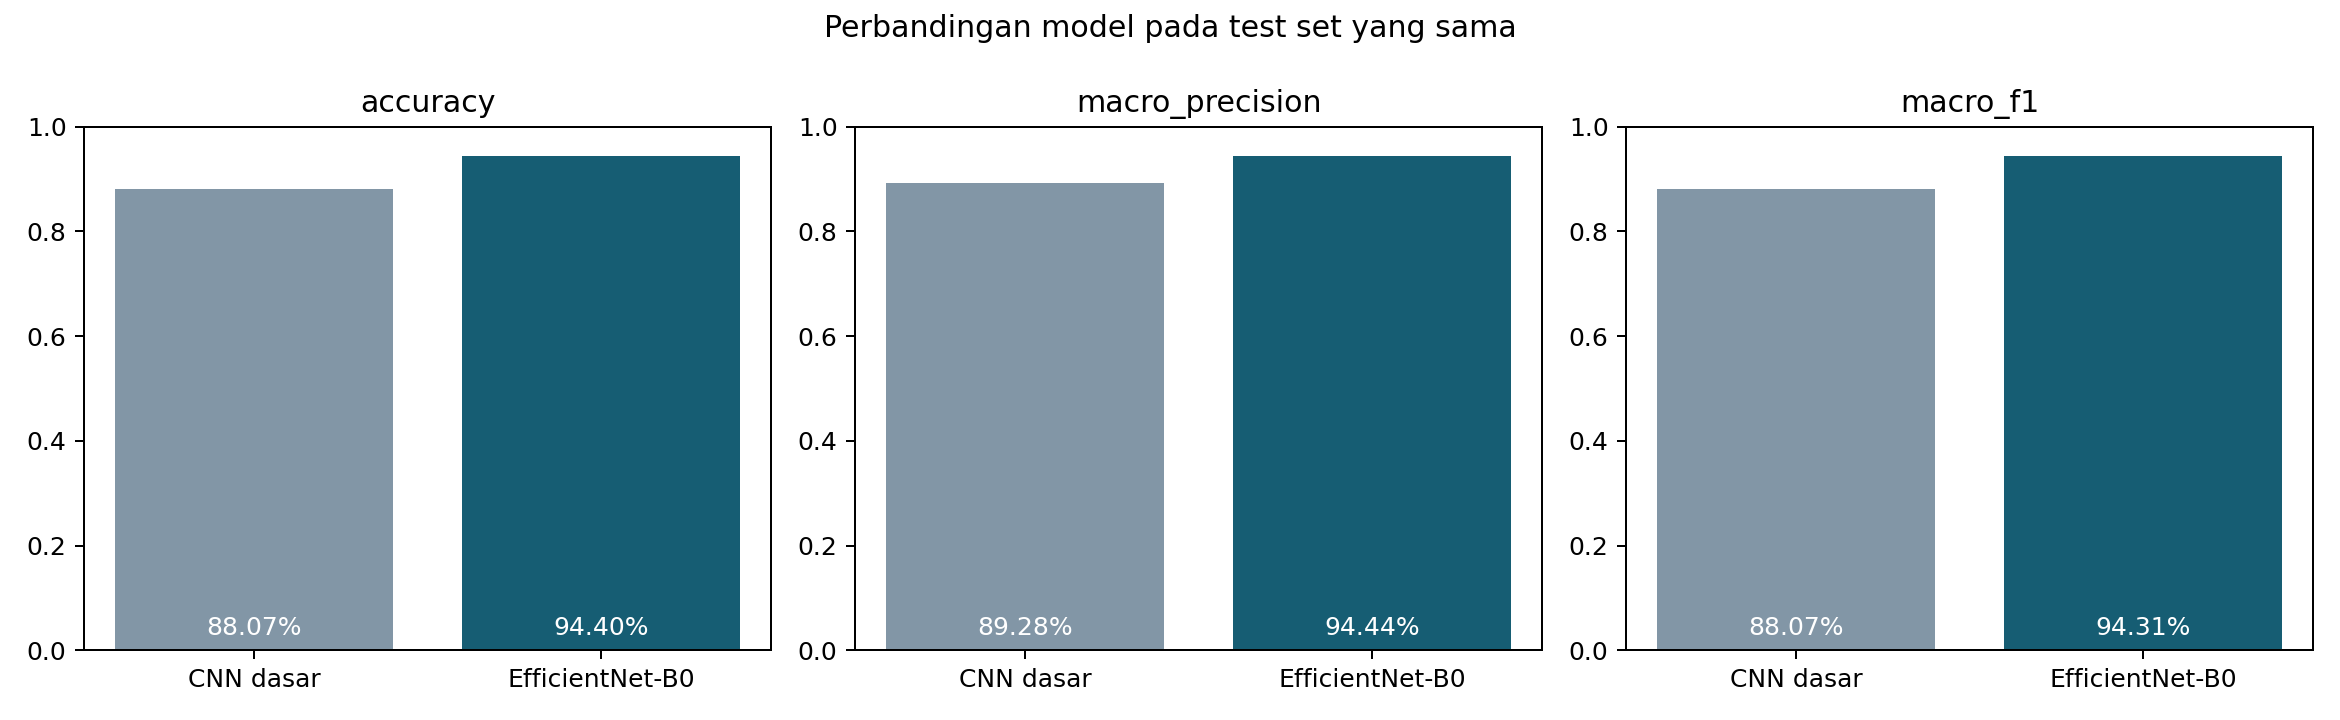

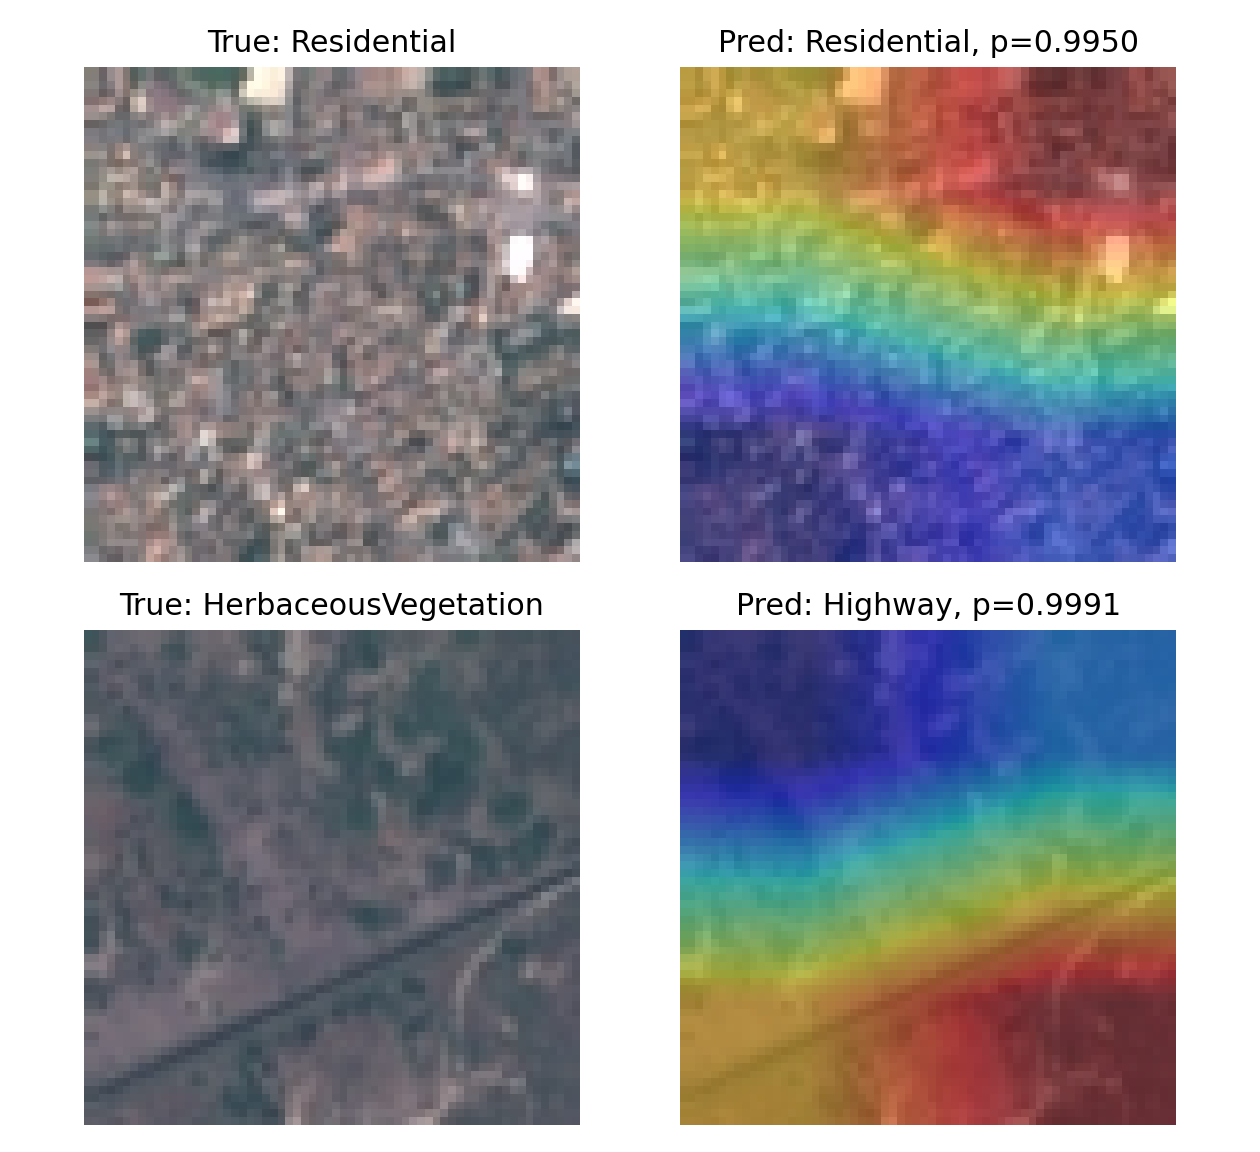

**Hasil yang Diperoleh**

EfficientNet memiliki macro-F1 **lebih tinggi** daripada baseline (Δ **+0.0625**) dan Δ accuracy **+6.32 poin persentase**. Kelas dengan F1 terendah: **PermanentCrop**. Checkpoint dan threshold yang sama dipakai pada paket aplikasi `deploy/space_package`.

**Temuan Awal**

Tujuan membangun serta mengevaluasi klasifikasi multikelas telah ditunjukkan melalui holdout dan dua fitur. Generalisasi geografis, kalibrasi probabilitas formal, dan penilaian kualitatif Grad-CAM masih terbatas. Status publikasi harus mengikuti bukti nyata.

In [11]:
from src.postprocess import run as postprocess
summary=postprocess('.')
display(IPImage(filename='artifacts/eksperimen/model_comparison.png'))
display(IPImage(filename='artifacts/eksperimen/gradcam_correct_and_wrong.png'))
subprocess.run([sys.executable,'scripts/package_for_space.py'],check=True,capture_output=True)
delta_f1=eff['test_metrics']['macro_f1']-base['test_metrics']['macro_f1']
delta_acc=eff['test_metrics']['accuracy']-base['test_metrics']['accuracy']
hardest=min(CLASS_NAMES,key=lambda c:eff['classification_report'][c]['f1-score'])
verdict='lebih tinggi' if delta_f1>0 else ('lebih rendah' if delta_f1<0 else 'sama')
display(Markdown(f"**Hasil yang Diperoleh**\n\nEfficientNet memiliki macro-F1 **{verdict}** daripada baseline (Δ **{delta_f1:+.4f}**) dan Δ accuracy **{delta_acc*100:+.2f} poin persentase**. Kelas dengan F1 terendah: **{hardest}**. Checkpoint dan threshold yang sama dipakai pada paket aplikasi `deploy/space_package`.\n\n**Temuan Awal**\n\nTujuan membangun serta mengevaluasi klasifikasi multikelas telah ditunjukkan melalui holdout dan dua fitur. Generalisasi geografis, kalibrasi probabilitas formal, dan penilaian kualitatif Grad-CAM masih terbatas. Status publikasi harus mengikuti bukti nyata."))
print('Paket aplikasi: deploy/space_package')
if 'google.colab' in sys.modules:
    import tempfile
    from google.colab import files
    destination = Path(tempfile.mkdtemp(prefix='eurosat-export-'))/'eurosat_gradio'
    export = shutil.make_archive(str(destination), 'zip', PROJECT/'deploy/space_package')
    files.download(export)
